# Approval strategy

**Question.** Which loans should a lender approve?

**Value model.** A repaid loan earns scheduled interest scaled for prepayment. A defaulted loan loses a share of the amount lent. The data has no payment or recovery fields, so both are assumptions, tested below.

**Rule.** Policies are chosen on the validation period and scored once on the test period.

In [1]:
import warnings; warnings.filterwarnings("ignore")
import sys, json, os
sys.path.insert(0, "../scripts")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from common import *
pd.set_option("display.width", 150); pd.set_option("display.max_columns", 30)
plt.rcParams.update({"figure.dpi": 130, "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "axes.axisbelow": True, "grid.color": "#e6e6e3", "font.size": 10})
ACC, MUTE, INK, BAD = "#20808D", "#9a9a94", "#2b2b2b", "#C8452F"
os.makedirs("../outputs/charts", exist_ok=True); os.makedirs("../outputs/tables", exist_ok=True)
def save_metrics(k, v):
    p = "../outputs/metrics.json"; m = json.load(open(p)) if os.path.exists(p) else {}
    m[k] = v; json.dump(m, open(p, "w"), indent=2, default=float)


In [2]:
va = pd.read_parquet("../data/interim/validation_scored.parquet"); te = pd.read_parquet("../data/interim/test_scored.parquet")
LGD, INT = 0.60, 0.75
def real(x, lgd=LGD, i=INT): return value_per_loan(x, x.target, lgd, i)
def exp(x, col="pd", lgd=LGD, i=INT): return value_per_loan(x, x[col], lgd, i)
def summary(x, keep, name, lgd=LGD, i=INT):
    k = x[keep]; v = real(k, lgd, i).sum()
    return dict(policy=name, approval_rate=100 * keep.mean(), default_rate=100 * k.target.mean(), avg_rate=(k.int_rate * k.loan_amnt).sum() / k.loan_amnt.sum(), lent_m=k.loan_amnt.sum() / 1e6, credit_loss_m=lgd * k.loan_amnt[k.target == 1].sum() / 1e6, value_m=v / 1e6, return_pct=100 * v / k.loan_amnt.sum())
print("Approve all, test:", summary(te, pd.Series(True, index=te.index), "all"))

Approve all, test: {'policy': 'all', 'approval_rate': np.float64(100.0), 'default_rate': np.float64(14.708819250967725), 'avg_rate': np.float64(10.876260100555914), 'lent_m': np.float64(2079.832925), 'credit_loss_m': np.float64(178.281015), 'value_m': np.float64(50.803386689999996), 'return_pct': np.float64(2.4426667199722303)}


## Cutoff curve

For each maximum predicted default rate, what happens to volume, defaults and value?

Best validation cutoff: 0.22


,sample,cutoff,approval_rate,default_rate,avg_rate,lent_m,credit_loss_m,value_m,return_pct
9,test,0.08,22.86,5.03,7.82,551.68,16.77,32.11,5.82
17,test,0.12,43.84,7.52,8.76,991.14,43.96,52.05,5.25
25,test,0.16,62.44,9.61,9.45,1356.19,76.16,62.32,4.60
33,test,0.20,76.67,11.20,9.93,1628.37,106.04,65.75,4.04
41,test,0.24,86.77,12.44,10.30,1819.43,131.64,64.32,3.53
49,test,0.28,93.17,13.39,10.55,1942.35,151.05,60.60,3.12
57,test,0.32,96.92,14.03,10.71,2015.60,164.09,57.00,2.83
65,test,0.36,98.80,14.40,10.80,2053.23,171.70,54.15,2.64


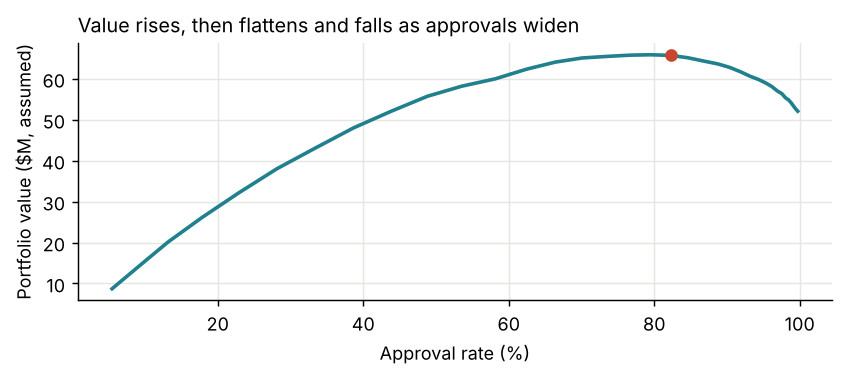

In [3]:
rows = []
for c in np.arange(0.04, 0.42, 0.01):
    for n, x in (("validation", va), ("test", te)):
        rows.append(dict(sample=n, cutoff=c, **summary(x, x["pd"] <= c, f"{c:.2f}")))
cv = pd.DataFrame(rows).drop(columns="policy"); cv.to_csv("../outputs/tables/cutoff_curve.csv", index=False)
vc = cv[cv["sample"] == "validation"]; best = float(vc.loc[vc.value_m.idxmax(), "cutoff"]); print("Best validation cutoff:", round(best, 2)); display(cv[(cv["sample"] == "test") & cv.cutoff.round(2).isin([.08, .12, .16, .2, .24, .28, .32, .36])].round(2))
t = cv[cv["sample"] == "test"]; fig, ax = plt.subplots(figsize=(6.6, 3)); ax.plot(t.approval_rate, t.value_m, color=ACC, lw=2); ax.scatter([t.loc[(t.cutoff - best).abs().idxmin(), "approval_rate"]], [t.loc[(t.cutoff - best).abs().idxmin(), "value_m"]], color=BAD, zorder=3)
ax.set_xlabel("Approval rate (%)"); ax.set_ylabel("Portfolio value ($M, assumed)"); ax.set_title("Value rises, then flattens and falls as approvals widen", loc="left", fontsize=11); plt.tight_layout(); plt.savefig("../outputs/charts/cutoff_curve.png"); plt.show()

## Policy comparison on the test period

The grade policy approves the safest sub-grades up to the same approval rate. The expected value rules approve a loan when expected value is positive, which counts its interest as well as its risk. The combined rows use the model that also sees the rate and grade. The recommended policy is the one with the best validation value, not the best test value.

In [4]:
def same_rate_grade(x, r):
    o = x.sort_values(["sub_grade_num", "int_rate"]); k = pd.Series(False, index=x.index); k.loc[o.index[: int(r * len(x))]] = True; return k
def best_cut(col):
    return max(np.arange(0.04, 0.42, 0.01), key=lambda c: real(va[va[col] <= c]).sum())
cp = best_cut("pd_plus"); print("Combined model cutoff:", round(cp, 2))
def policies(x):
    m = x["pd"] <= best
    return {"Approve all": pd.Series(True, index=x.index), "Grade policy, same approval as score": same_rate_grade(x, m.mean()), "Application score cutoff": m, "Application score, expected value rule": exp(x) > 0, "Combined score cutoff": x["pd_plus"] <= cp, "Combined score, expected value rule": exp(x, "pd_plus") > 0}
pv = policies(va); pt = policies(te)
tb = pd.DataFrame([summary(te, k, n) for n, k in pt.items()]); tb["validation_value_m"] = [real(va[k]).sum() / 1e6 for k in pv.values()]; tb["value_vs_all_m"] = tb.value_m - tb.value_m.iloc[0]; tb["loss_vs_all_pct"] = 100 * (tb.credit_loss_m / tb.credit_loss_m.iloc[0] - 1)
tb.to_csv("../outputs/tables/policy_comparison.csv", index=False); display(tb.round(2))
rec = tb.iloc[tb.validation_value_m.values.argmax()].policy; print("Recommended on validation:", rec)
rng = np.random.default_rng(42); a = real(te).values
def boot(k1, k2):
    b, c = pt[k1].values, pt[k2].values; d = []
    for _ in range(1000):
        i = rng.integers(0, len(a), len(a)); d.append((a[i] * b[i]).sum() - (a[i] * c[i]).sum())
    return ((a * b).sum() - (a * c).sum()) / 1e6, *(np.percentile(d, [2.5, 97.5]) / 1e6)
b1 = boot("Application score cutoff", "Grade policy, same approval as score"); b2 = boot(rec, "Approve all"); print("Score minus grade:", np.round(b1, 2), "| Recommended minus approve all:", np.round(b2, 2))

Combined model cutoff: 0.24


,policy,approval_rate,default_rate,avg_rate,lent_m,credit_loss_m,value_m,return_pct,validation_value_m,value_vs_all_m,loss_vs_all_pct
0,Approve all,100.00,14.71,10.88,2079.83,178.28,50.80,2.44,39.91,0.00,0.00
1,"Grade policy, same approval as score",82.23,11.95,9.68,1731.02,119.72,56.99,3.29,43.54,6.19,-32.85
2,Application score cutoff,82.23,11.85,10.14,1734.82,119.58,65.69,3.79,50.49,14.89,-32.93
3,"Application score, expected value rule",75.43,12.50,10.57,1601.14,115.82,60.50,3.78,47.01,9.69,-35.03
4,Combined score cutoff,85.32,11.93,10.01,1784.03,122.90,65.76,3.69,50.00,14.95,-31.07
5,"Combined score, expected value rule",79.42,11.58,10.06,1677.50,112.12,66.51,3.97,49.85,15.71,-37.11


Recommended on validation: Application score cutoff


Score minus grade: [ 8.7   7.05 10.35] | Recommended minus approve all: [14.89 13.28 16.45]


## Why does a tied AUC produce more value?

The score ignores the interest rate, so at the same approval rate it keeps more higher-rate loans than the grade policy does. The table splits the value gap into interest earned and credit losses. Higher-rate loans may also carry risks this simple value model misses, such as a higher chance of early default, so this gap should not be read as better risk selection.

In [5]:
def parts(k):
    x = te[k]; return dict(interest_m=(value_per_loan(x, 0 * x.target, LGD, INT).sum() - value_per_loan(x[x.target == 1], 0 * x.target[x.target == 1], LGD, INT).sum()) / 1e6, credit_loss_m=LGD * x.loan_amnt[x.target == 1].sum() / 1e6)
pa, pb = parts(pt["Application score cutoff"]), parts(pt["Grade policy, same approval as score"]); dcmp = pd.DataFrame([dict(item=k, score=pa[k], grade=pb[k], difference=pa[k] - pb[k]) for k in pa]); dcmp.to_csv("../outputs/tables/value_gap_decomposition.csv", index=False); display(dcmp.round(2))

,item,score,grade,difference
0,interest_m,185.28,176.71,8.56
1,credit_loss_m,119.58,119.72,-0.14


## Sensitivity

The assumptions drive the money figures. The first table re-tunes the cutoff for each scenario, which shows the best a lender could do if it knew the true assumptions. The second keeps the recommended cutoffs fixed, which is the honest test of a single rule.

In [6]:
g = []
for lgd in (0.45, 0.60, 0.75):
    for i in (0.60, 0.75, 0.90):
        cols = {}
        for n, col in (("score", "pd"), ("combined", "pd_plus")):
            c = max(np.arange(0.04, 0.42, 0.01), key=lambda z: real(va[va[col] <= z], lgd, i).sum()); cols[n] = (c, te[col] <= c)
        ev = exp(te, "pd_plus", lgd, i) > 0; kp = same_rate_grade(te, cols["score"][1].mean())
        g.append(dict(lgd=lgd, interest_share=i, score_cutoff=cols["score"][0], approval_rate=100 * cols["score"][1].mean(), all_m=real(te, lgd, i).sum() / 1e6, grade_m=real(te[kp], lgd, i).sum() / 1e6, score_m=real(te[cols["score"][1]], lgd, i).sum() / 1e6, combined_m=real(te[cols["combined"][1]], lgd, i).sum() / 1e6, combined_ev_m=real(te[ev], lgd, i).sum() / 1e6))
sg = pd.DataFrame(g); sg["best_policy"] = sg[["all_m", "grade_m", "score_m", "combined_m", "combined_ev_m"]].idxmax(axis=1); sg.to_csv("../outputs/tables/sensitivity_retuned.csv", index=False); display(sg.round(2))
fx = []
for lgd in (0.45, 0.55, 0.60, 0.75):
    for i in (0.60, 0.75, 0.90):
        fx.append(dict(lgd=lgd, interest_share=i, all_m=real(te, lgd, i).sum() / 1e6, score_fixed_m=real(te[te["pd"] <= best], lgd, i).sum() / 1e6, combined_fixed_m=real(te[te["pd_plus"] <= cp], lgd, i).sum() / 1e6))
ff = pd.DataFrame(fx); ff["score_gain_m"] = ff.score_fixed_m - ff.all_m; ff["combined_gain_m"] = ff.combined_fixed_m - ff.all_m; ff.to_csv("../outputs/tables/sensitivity_fixed_cutoff.csv", index=False); display(ff.round(2))
print("Fixed score cutoff beats approve all:", int((ff.score_gain_m > 0).sum()), "of", len(ff), "| fixed combined:", int((ff.combined_gain_m > 0).sum()), "of", len(ff))

,lgd,interest_share,score_cutoff,approval_rate,all_m,grade_m,score_m,combined_m,combined_ev_m,best_policy
0,0.45,0.60,0.25,88.72,49.56,52.75,57.75,58.75,58.48,combined_m
1,0.45,0.75,0.30,95.32,95.37,95.09,98.49,98.83,99.19,combined_ev_m
2,0.45,0.90,0.35,98.47,141.19,140.74,142.35,142.36,142.34,combined_m
3,0.60,0.60,0.15,58.14,4.99,28.26,34.29,35.38,35.46,combined_ev_m
4,0.60,0.75,0.22,82.23,50.80,56.99,65.69,65.76,66.51,combined_ev_m
5,0.60,0.90,0.25,88.72,96.62,96.30,103.77,103.64,104.11,combined_ev_m
6,0.75,0.60,0.13,48.82,-39.58,14.01,21.33,22.13,21.27,combined_m
7,0.75,0.75,0.15,58.14,6.23,35.32,42.87,44.22,44.32,combined_ev_m
8,0.75,0.90,0.22,82.23,52.05,62.40,72.85,73.06,74.27,combined_ev_m


,lgd,interest_share,all_m,score_fixed_m,combined_fixed_m,score_gain_m,combined_gain_m
0,0.45,0.60,49.56,58.53,58.75,8.98,9.19
1,0.45,0.75,95.37,95.59,96.48,0.22,1.11
2,0.45,0.90,141.19,132.64,134.21,-8.55,-6.98
3,0.55,0.60,19.84,38.60,38.27,18.76,18.43
4,0.55,0.75,65.66,75.66,76.00,10.00,10.34
5,0.55,0.90,111.48,112.71,113.73,1.24,2.25
6,0.60,0.60,4.99,28.64,28.03,23.65,23.04
7,0.60,0.75,50.80,65.69,65.76,14.89,14.95
8,0.60,0.90,96.62,102.75,103.49,6.13,6.87
9,0.75,0.60,-39.58,-1.26,-2.70,38.33,36.89


Fixed score cutoff beats approve all: 11 of 12 | fixed combined: 11 of 12


## Is the pricing right?

Does the rate charged cover risk in each grade? This is realised value by Lending Club grade on the test period, using the base assumptions.

In [7]:
gr = te.assign(v=real(te)).groupby("grade").agg(loans=("target", "size"), default_rate=("target", "mean"), predicted=("pd", "mean"), predicted_combined=("pd_plus", "mean"), avg_rate=("int_rate", "mean"), lent=("loan_amnt", "sum"), value=("v", "sum")).reset_index(); gr["return_pct"] = 100 * gr.value / gr.lent; gr["default_rate"] *= 100; gr["predicted"] *= 100; gr["predicted_combined"] *= 100
for lgd, i in ((0.45, 0.75), (0.55, 0.75), (0.60, 0.90), (0.75, 0.75)):
    gr[f"ret_lgd{int(lgd*100)}_int{int(i*100)}"] = te.assign(v=real(te, lgd, i)).groupby("grade").v.sum().values / te.groupby("grade").loan_amnt.sum().values * 100
gr.to_csv("../outputs/tables/grade_economics.csv", index=False); display(gr.round(2))
save_metrics("strategy", dict(lgd=LGD, interest_share=INT, cutoff=best, combined_cutoff=cp, recommended=rec, policies=tb.to_dict("records"), score_minus_grade=list(b1), rec_minus_all=list(b2), best_counts=sg.best_policy.value_counts().to_dict(), fixed_score_wins=int((ff.score_gain_m > 0).sum()), fixed_combined_wins=int((ff.combined_gain_m > 0).sum()), fixed_n=len(ff)))

,grade,loans,default_rate,predicted,predicted_combined,avg_rate,lent,value,return_pct,ret_lgd45_int75,ret_lgd55_int75,ret_lgd60_int90,ret_lgd75_int75
0,A,39493,5.15,7.71,5.56,6.80,576166250.0,27120511.62,4.71,5.46,4.96,6.25,3.96
1,B,55979,11.77,13.35,11.90,9.93,698319175.0,24709141.08,3.54,5.29,4.12,5.65,1.78
2,C,43742,19.80,18.08,19.04,13.17,526024675.0,5260464.30,1.00,3.99,2.00,3.59,-1.99
3,D,17322,26.38,21.57,24.77,16.65,211764125.0,-2350334.34,-1.11,2.95,0.24,1.92,-5.17
4,E,4817,33.53,24.94,30.61,18.96,58892600.0,-2855969.76,-4.85,0.28,-3.14,-1.72,-9.98
5,F,733,43.11,27.80,35.22,23.34,7241275.0,-762020.28,-10.52,-3.78,-8.28,-7.23,-17.27
6,G,150,53.33,30.39,39.35,27.35,1424825.0,-318405.93,-22.35,-13.24,-19.31,-19.53,-31.46
